# Análise MapBiomas

## 1. Objetivos

Este notebook tem como objetivo analisar as mudanças de uso e cobertura da terra no município de Teresópolis, Rio de Janeiro, entre 1985 e 2025, utilizando dados do MapBiomas — Coleção 11.

A análise busca:

- Identificar as classes de uso e cobertura da terra presentes no município em cada ano.
- Quantificar a área ocupada por cada classe.
- Comparar as mudanças absolutas e relativas entre 1985 e 2025.
- Identificar as principais transições entre classes no período.
- Produzir mapas, tabelas e gráficos que apoiem a interpretação das mudanças na paisagem municipal.

As análises utilizarão os rasters previamente recortados no Notebook 02, a legenda oficial da Coleção 11 e procedimentos de validação para assegurar a consistência dos resultados.

## 2. Etapas da análise

- Configuração do ambiente e dos caminhos.
- Carregamento e validação dos rasters.
- Preparação e validação da legenda oficial do MapBiomas Coleção 11.
- Visualização temática dos anos de 1985 e 2025.
- Quantificação das áreas por classe.
- Comparação temporal das classes.
- Construção e análise da matriz de transição.
- Elaboração de tabelas, gráficos e produtos cartográficos.
- Síntese dos resultados e conclusão.

## 3. Bibliotecas

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pyproj import Geod
from matplotlib.colors import LogNorm
from rasterio.transform import xy
from matplotlib.lines import Line2D

## 4. Configuração do ambiente e dos caminhos

### Detecção automática da raiz do projeto

In [2]:
# Identificar a raiz do projeto a partir do diretório atual
diretorio_atual = Path.cwd().resolve()

candidatos = [
    diretorio_atual,
    *diretorio_atual.parents
]

raizes_encontradas = [
    caminho
    for caminho in candidatos
    if caminho.name == "projeto_teresopolis"
    and (caminho / "notebooks").is_dir()
    and (caminho / "dados").is_dir()
]

if not raizes_encontradas:
    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto "
        "'projeto_teresopolis'. Verifique o diretório de "
        "execução do notebook."
    )

PROJECT_ROOT = raizes_encontradas[0]

print("Raiz do projeto:", PROJECT_ROOT)

Raiz do projeto: G:\Meu Drive\projeto_teresopolis


### Definição dos caminhos

In [3]:
# Diretórios do projeto
DATA_DIR = PROJECT_ROOT / "dados"
INTERMEDIARIOS_DIR = DATA_DIR / "intermediarios"
RESULTADOS_DIR = PROJECT_ROOT / "resultados" / "mapbiomas"

# Rasters recortados no Notebook 02
arquivo_1985 = INTERMEDIARIOS_DIR / "mapbiomas_teresopolis_1985.tif"
arquivo_2025 = INTERMEDIARIOS_DIR / "mapbiomas_teresopolis_2025.tif"

print("Raster de 1985:", arquivo_1985)
print("Raster de 2025:", arquivo_2025)
print("Diretório de resultados:", RESULTADOS_DIR)

Raster de 1985: G:\Meu Drive\projeto_teresopolis\dados\intermediarios\mapbiomas_teresopolis_1985.tif
Raster de 2025: G:\Meu Drive\projeto_teresopolis\dados\intermediarios\mapbiomas_teresopolis_2025.tif
Diretório de resultados: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas


### Validar os arquivos de entrada

In [4]:
arquivos_entrada = {
    "1985": arquivo_1985,
    "2025": arquivo_2025,
}

for ano, caminho in arquivos_entrada.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Raster de {ano} não encontrado: {caminho}"
        )

    print(f"Raster de {ano}: encontrado")

Raster de 1985: encontrado
Raster de 2025: encontrado


## 5. Carregamento e inspeção dos rasters
Nesta seção, serão inspecionados os rasters de uso e cobertura da terra de 1985 e 2025, verificando suas características espaciais e os metadados necessários às análises temporais.

A validação permitirá confirmar a compatibilidade entre os arquivos e identificar eventuais diferenças que possam comprometer a comparação entre os anos.

### Inspecionar os metadados dos rasters

In [5]:
metadados = {}

for ano, caminho in arquivos_entrada.items():
    with rasterio.open(caminho) as src:
        metadados[ano] = {
            "CRS": src.crs,
            "Largura (pixels)": src.width,
            "Altura (pixels)": src.height,
            "Resolução": src.res,
            "Bandas": src.count,
            "Tipo de dado": src.dtypes[0],
            "NoData": src.nodata,
            "Transformação": src.transform,
            "Limites": src.bounds,
        }

df_metadados = pd.DataFrame(metadados).T
df_metadados


,CRS,Largura (pixels),Altura (pixels),Resolução,Bandas,Tipo de dado,NoData,Transformação,Limites
1985,"(proj, datum, no_defs)",1245,1286,"(0.00026949458523585647, 0.00026949458523585647)",1,uint8,255.0,"(0.00026949458523585647, 0.0, -43.046370099723...","(-43.04637009972336, -22.47126700072142, -42.7..."
2025,"(proj, datum, no_defs)",1245,1286,"(0.00026949458523585647, 0.00026949458523585647)",1,uint8,255.0,"(0.00026949458523585647, 0.0, -43.046370099723...","(-43.04637009972336, -22.47126700072142, -42.7..."


### Identificar os códigos presentes em cada ano

In [6]:
codigos_por_ano = {}

for ano, caminho in arquivos_entrada.items():
    with rasterio.open(caminho) as src:
        dados = src.read(1, masked=True)
        valores, contagens = np.unique(
            dados.compressed(),
            return_counts=True
        )

        codigos_por_ano[ano] = set(valores.tolist())

        print(f"\nAno: {ano}")
        print("Pixels válidos:", int(contagens.sum()))
        print("Quantidade de códigos:", len(valores))
        print("Códigos encontrados:", valores.tolist())


Ano: 1985
Pixels válidos: 933319
Quantidade de códigos: 12
Códigos encontrados: [3, 9, 11, 12, 15, 21, 24, 25, 29, 30, 33, 41]

Ano: 2025
Pixels válidos: 933319
Quantidade de códigos: 12
Códigos encontrados: [3, 9, 11, 12, 15, 21, 24, 25, 29, 30, 32, 33]


### Conferir os códigos na legenda

In [7]:
# Caminho da legenda oficial
arquivo_legenda = (
    DATA_DIR
    / "brutos"
    / "uso_cobertura"
    / "legend_code_mapbiomas_brazil_collection_11.csv"
)

if not arquivo_legenda.is_file():
    raise FileNotFoundError(
        "Legenda oficial não encontrada. Baixe o CSV da "
        "Coleção 11 e salve no caminho indicado."
    )

# Inspecionar o arquivo sem presumir os nomes das colunas
legenda_preview = pd.read_csv(
    arquivo_legenda,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

print("Dimensões:", legenda_preview.shape)
print("\nColunas:")
print(legenda_preview.columns.tolist())

display(legenda_preview.head())

Dimensões: (33, 4)

Colunas:
['class_id', 'class_name_pt_br', 'class_name_en', 'hex_code']


,class_id,class_name_pt_br,class_name_en,hex_code
0,3,Formação Florestal,Forest Formation,#1f8d49
1,6,Floresta Alagável,Floodable Forest,#007785
2,4,Formação Savânica,Savanna Formation,#7dc975
3,7,Savana Alagada (beta),Flooded Savanna (beta),#228c70
4,5,Mangue,Mangrove,#04381d


## 6. Preparação e validação da legenda oficial

Nesta seção, a legenda oficial do MapBiomas Coleção 11 será utilizada para associar os códigos numéricos presentes nos rasters aos nomes das classes e às respectivas cores.

A validação verificará se os códigos encontrados nos rasters de 1985 e 2025 possuem correspondência na legenda, garantindo consistência na identificação das classes antes das análises quantitativas e cartográficas.

###  Validar a legenda

In [8]:
# Verificar a integridade da legenda
colunas_esperadas = {
    "class_id",
    "class_name_pt_br",
    "class_name_en",
    "hex_code",
}

if not colunas_esperadas.issubset(legenda_preview.columns):
    raise ValueError("A legenda não contém todas as colunas esperadas.")

legenda = legenda_preview.copy()

# Garantir que os códigos sejam numéricos e inteiros
legenda["class_id"] = pd.to_numeric(
    legenda["class_id"],
    errors="raise"
)

if not (legenda["class_id"] % 1 == 0).all():
    raise ValueError("Foram encontrados códigos que não são inteiros.")

legenda["class_id"] = legenda["class_id"].astype(int)

# Verificar duplicidade de códigos e campos vazios
if legenda["class_id"].duplicated().any():
    duplicados = legenda.loc[
        legenda["class_id"].duplicated(keep=False),
        "class_id"
    ].tolist()
    raise ValueError(f"Códigos duplicados na legenda: {duplicados}")

if legenda[list(colunas_esperadas)].isna().any().any():
    raise ValueError("A legenda contém valores ausentes.")

print("Registros na legenda:", len(legenda))
print("Códigos únicos:", legenda["class_id"].nunique())
print("Códigos duplicados: nenhum")
print("Validação estrutural concluída.")

Registros na legenda: 33
Códigos únicos: 33
Códigos duplicados: nenhum
Validação estrutural concluída.


### Cruzar legenda e códigos dos rasters

In [9]:
# Reunir os códigos encontrados nos dois anos
codigos_raster = sorted(
    codigos_por_ano["1985"] | codigos_por_ano["2025"]
)

# Preparar a tabela de correspondência
tabela_codigos = pd.DataFrame({
    "class_id": codigos_raster
})

tabela_codigos = tabela_codigos.merge(
    legenda[
        ["class_id", "class_name_pt_br", "hex_code"]
    ],
    on="class_id",
    how="left",
    validate="one_to_one"
)

# Indicar em quais anos cada código ocorre
tabela_codigos["presente_1985"] = (
    tabela_codigos["class_id"].isin(codigos_por_ano["1985"])
)

tabela_codigos["presente_2025"] = (
    tabela_codigos["class_id"].isin(codigos_por_ano["2025"])
)

# Identificar códigos sem correspondência
codigos_sem_legenda = tabela_codigos.loc[
    tabela_codigos["class_name_pt_br"].isna(),
    "class_id"
].tolist()

display(tabela_codigos)

if codigos_sem_legenda:
    print("Códigos sem correspondência na legenda:", codigos_sem_legenda)
else:
    print("Todos os códigos encontrados possuem correspondência na legenda.")

,class_id,class_name_pt_br,hex_code,presente_1985,presente_2025
0,3,Formação Florestal,#1f8d49,True,True
1,9,Silvicultura,#7a5900,True,True
2,11,Campo Alagado e Área Pantanosa,#519799,True,True
3,12,Formação Campestre,#d6bc74,True,True
4,15,Pastagem,#edde8e,True,True
5,21,Mosaico de usos,#ffefc3,True,True
6,24,Área Urbanizada,#d4271e,True,True
7,25,Outras Área não Vegetadas,#db4d4f,True,True
8,29,Afloramento Rochoso,#ad5100,True,True
9,30,Mineração,#9c0027,True,True


Todos os códigos encontrados possuem correspondência na legenda.


### Investigar as classes 32 e 41 nos rasters recortados

#### Preparar os arquivos e verificar os dados

In [10]:
# Arquivos de referência
arquivo_limite = INTERMEDIARIOS_DIR / "limite_teresopolis.gpkg"

arquivos_investigacao = {
    1985: {
        "raster": arquivo_1985,
        "classe": 41,
        "nome": "Outras Lavouras Temporárias",
    },
    2025: {
        "raster": arquivo_2025,
        "classe": 32,
        "nome": "Apicum",
    },
}

if not arquivo_limite.is_file():
    raise FileNotFoundError(
        f"Limite municipal não encontrado: {arquivo_limite}"
    )

limite_municipal = gpd.read_file(arquivo_limite)

if limite_municipal.empty:
    raise ValueError("O arquivo do limite municipal está vazio.")

if limite_municipal.crs is None:
    raise ValueError("O limite municipal não possui CRS definido.")

print("CRS do limite:", limite_municipal.crs)
print("Geometrias do limite:", len(limite_municipal))
print("Geometrias vazias:", limite_municipal.geometry.is_empty.sum())
print("Geometrias inválidas:", (~limite_municipal.geometry.is_valid).sum())

CRS do limite: EPSG:4674
Geometrias do limite: 1
Geometrias vazias: 0
Geometrias inválidas: 0


C:\Users\claud\anaconda3\envs\AmbGEO\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


In [11]:
def identificar_manchas_8(mascara):
    """
    Identifica componentes conectados usando 8 vizinhos.

    Parâmetros
    ----------
    mascara : np.ndarray
        Matriz booleana com True nos pixels da classe investigada.

    Retorna
    -------
    rotulos : np.ndarray
        Matriz de rótulos. Zero representa pixels fora da classe.
    quantidade : int
        Número de manchas identificadas.
    """
    mascara = np.asarray(mascara, dtype=bool)
    altura, largura = mascara.shape

    rotulos = np.zeros((altura, largura), dtype=np.int32)
    quantidade = 0

    # Deslocamentos dos oito vizinhos
    vizinhos = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),            (0, 1),
        (1, -1),  (1, 0),   (1, 1),
    ]

    for linha, coluna in zip(*np.where(mascara & (rotulos == 0))):
        if rotulos[linha, coluna] != 0:
            continue

        quantidade += 1
        rotulos[linha, coluna] = quantidade
        pilha = [(linha, coluna)]

        while pilha:
            lin, col = pilha.pop()

            for dlin, dcol in vizinhos:
                viz_lin = lin + dlin
                viz_col = col + dcol

                if (
                    0 <= viz_lin < altura
                    and 0 <= viz_col < largura
                    and mascara[viz_lin, viz_col]
                    and rotulos[viz_lin, viz_col] == 0
                ):
                    rotulos[viz_lin, viz_col] = quantidade
                    pilha.append((viz_lin, viz_col))

    return rotulos, quantidade

#### Contar pixels e caracterizar as manchas

In [12]:
# Contagem de pixels e análise de componentes conectados
# Conectividade de 8 vizinhos: inclui contatos diagonais.

resultados_classes = []
resultados_manchas = []
ocorrencias = {}

for ano, info in arquivos_investigacao.items():
    classe = info["classe"]
    nome_classe = info["nome"]
    caminho = info["raster"]

    with rasterio.open(caminho) as src:
        raster = src.read(1, masked=True)
        transform = src.transform
        crs_raster = src.crs
        nodata = src.nodata

    # Máscara de pixels pertencentes à classe investigada
    mascara_classe = (
        (~np.ma.getmaskarray(raster))
        & (raster.data == classe)
    )

    quantidade_pixels = int(mascara_classe.sum())

    # Identificar manchas contíguas
    rotulos, quantidade_manchas = identificar_manchas_8(
        mascara_classe
    )

    tamanhos_manchas = (
        np.bincount(rotulos.ravel())[1:]
        if quantidade_manchas > 0
        else np.array([], dtype=int)
    )

    # Coordenadas dos centros dos pixels
    linhas, colunas = np.where(mascara_classe)

    xs, ys = xy(
        transform,
        linhas,
        colunas,
        offset="center"
    )

    pontos = gpd.GeoDataFrame(
        {
            "ano": ano,
            "classe_id": classe,
            "classe": nome_classe,
            "linha": linhas,
            "coluna": colunas,
            "componente": rotulos[linhas, colunas],
        },
        geometry=gpd.points_from_xy(xs, ys),
        crs=crs_raster
    )

    ocorrencias[ano] = {
        "mascara": mascara_classe,
        "rotulos": rotulos,
        "pontos": pontos,
        "transform": transform,
        "crs": crs_raster,
        "tamanhos": tamanhos_manchas,
        "nodata": nodata,
    }

    resultados_classes.append({
        "ano": ano,
        "classe_id": classe,
        "classe": nome_classe,
        "pixels": quantidade_pixels,
        "manchas_8_conectadas": int(quantidade_manchas),
        "maior_mancha_pixels": (
            int(tamanhos_manchas.max())
            if len(tamanhos_manchas) else 0
        ),
        "pixels_em_manchas_de_1_pixel": int(
            (tamanhos_manchas == 1).sum()
        ),
    })

    for identificador, tamanho in enumerate(
        tamanhos_manchas,
        start=1
    ):
        resultados_manchas.append({
            "ano": ano,
            "classe_id": classe,
            "classe": nome_classe,
            "componente": identificador,
            "pixels": int(tamanho),
        })

df_investigacao = pd.DataFrame(resultados_classes)
df_manchas = pd.DataFrame(resultados_manchas)

display(df_investigacao)

,ano,classe_id,classe,pixels,manchas_8_conectadas,maior_mancha_pixels,pixels_em_manchas_de_1_pixel
0,1985,41,Outras Lavouras Temporárias,64,1,64,0
1,2025,32,Apicum,73,3,45,0


#### Localizar as ocorrências no município

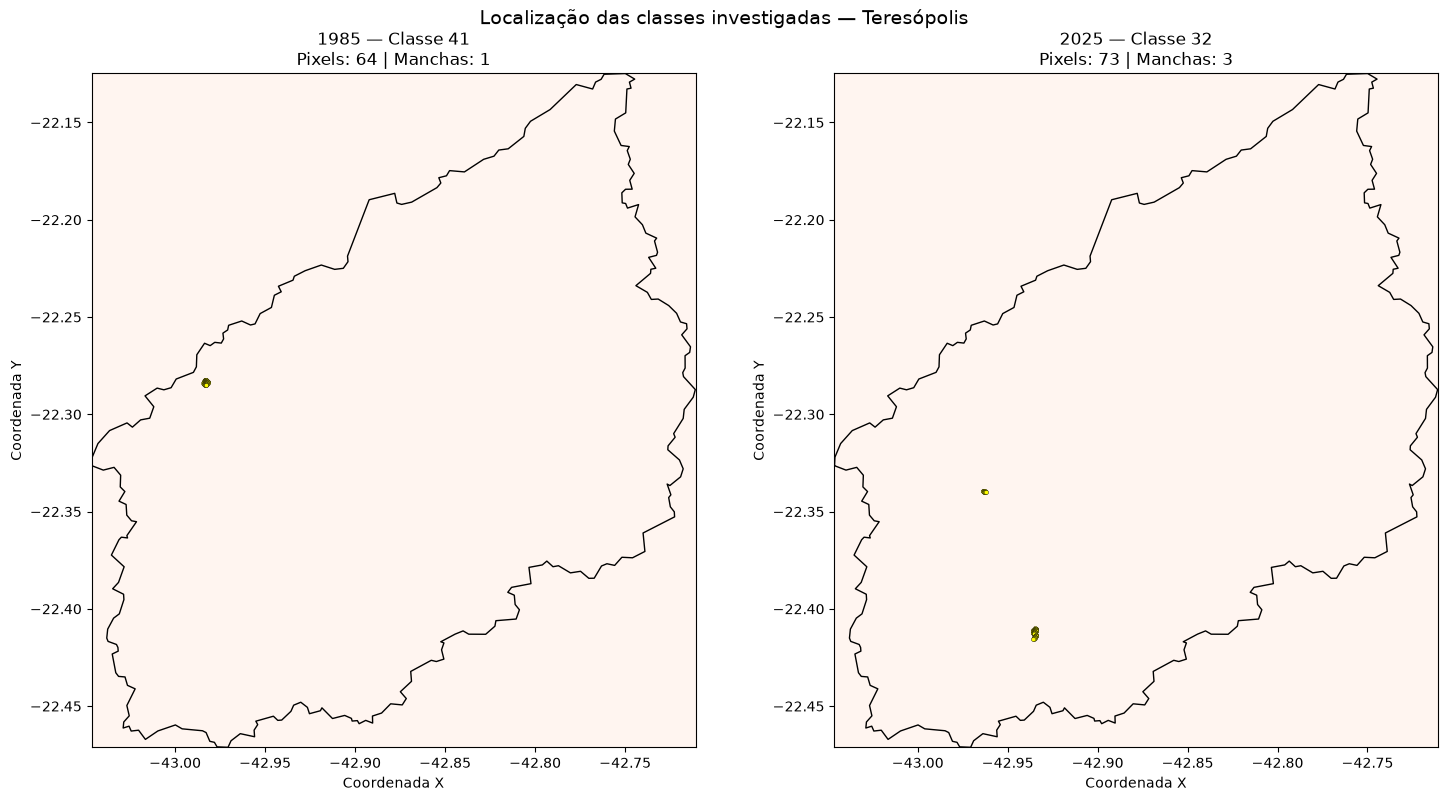

In [13]:
# Mapa das ocorrências das classes 41 e 32
# O limite é convertido para o CRS dos rasters para a visualização.

fig, eixos = plt.subplots(1, 2, figsize=(15, 8))

for ax, ano in zip(eixos, [1985, 2025]):
    info = arquivos_investigacao[ano]
    dados = ocorrencias[ano]

    with rasterio.open(info["raster"]) as src:
        limites = src.bounds

    limite_plot = limite_municipal.to_crs(dados["crs"])

    ax.imshow(
        dados["mascara"],
        extent=[
            limites.left,
            limites.right,
            limites.bottom,
            limites.top
        ],
        origin="upper",
        cmap="Reds",
        interpolation="nearest"
    )

    limite_plot.boundary.plot(
        ax=ax,
        color="black",
        linewidth=1.0
    )

    pontos = dados["pontos"]

    if not pontos.empty:
        pontos.plot(
            ax=ax,
            color="yellow",
            markersize=9,
            edgecolor="black",
            linewidth=0.3
        )

    ax.set_title(
        f'{ano} — Classe {info["classe"]}\n'
        f'Pixels: {len(pontos):,} | '
        f'Manchas: {len(dados["tamanhos"]):,}'
    )
    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Coordenada Y")

fig.suptitle(
    "Localização das classes investigadas — Teresópolis",
    fontsize=14
)
fig.tight_layout()
plt.show()

### Comparar com os rasters originais

In [14]:
# Caminhos dos rasters originais do MapBiomas Collection 11

BRUTOS_USO_DIR = (
    DATA_DIR / "brutos" / "uso_cobertura"
)

arquivos_originais = {
    1985: BRUTOS_USO_DIR / "brazil_coverage-col11_1985.tif",
    2025: BRUTOS_USO_DIR / "brazil_coverage-col11_2025.tif",
}

for ano, caminho in arquivos_originais.items():
    print(
        f"{ano}: {'Encontrado' if caminho.is_file() else 'NÃO ENCONTRADO'}"
        f" — {caminho}"
    )

1985: Encontrado — G:\Meu Drive\projeto_teresopolis\dados\brutos\uso_cobertura\brazil_coverage-col11_1985.tif
2025: Encontrado — G:\Meu Drive\projeto_teresopolis\dados\brutos\uso_cobertura\brazil_coverage-col11_2025.tif


#### Verificação de ocorrências de classes específicas

Durante a análise dos rasters de uso e cobertura da terra, foram identificadas duas ocorrências que mereceram verificação adicional: a classe 41 — Outras Lavouras Temporárias, no raster de 1985, e a classe 32 — Apicum, no raster de 2025.

A análise espacial identificou 64 pixels da classe 41, distribuídos em uma única mancha, e 73 pixels da classe 32, distribuídos em três manchas, considerando conectividade de oito vizinhos. Nenhuma das classes apresentou manchas constituídas por apenas um pixel.

A comparação com os rasters originais do MapBiomas Collection 11 confirmou que todos os pixels investigados estavam presentes nos arquivos de origem e mantinham os mesmos códigos de classificação. Além disso, os centros de todos esses pixels foram identificados dentro do polígono municipal de Teresópolis.

Esses resultados indicam que as ocorrências não foram introduzidas exclusivamente pelo processo de recorte e que apresentam continuidade espacial na resolução analisada. Entretanto, essa verificação não permite confirmar, isoladamente, a exatidão temática das classificações nem explicar sua ocorrência na área de estudo.

Por esse motivo, as classes foram mantidas na análise, sem correção ou exclusão arbitrária. Suas ocorrências devem ser consideradas na interpretação dos resultados, reconhecendo-se que uma avaliação definitiva de sua plausibilidade temática exigiria consulta a fontes cartográficas complementares e investigação espacial mais detalhada.

## 7. Visualização temática dos anos analisados

Nesta seção, serão elaborados mapas temáticos de uso e cobertura da terra para os anos de 1985 e 2025, utilizando os códigos de classe e as cores da legenda oficial do MapBiomas Coleção 11.

Os mapas permitirão observar a distribuição espacial das classes no município de Teresópolis e fornecerão uma base visual para a comparação temporal.

Os pixels classificados como NoData serão representados separadamente das classes temáticas e não serão interpretados como uma categoria de uso ou cobertura da terra.

### Preparar as cores oficiais

In [15]:
# Criar o dicionário de cores a partir da legenda oficial
cores_classes = {
    int(linha.class_id): linha.hex_code
    for linha in legenda.itertuples(index=False)
}

# Conferir se todos os códigos dos rasters possuem cor definida
codigos_raster = sorted(
    codigos_por_ano["1985"] | codigos_por_ano["2025"]
)

codigos_sem_cor = [
    codigo for codigo in codigos_raster
    if codigo not in cores_classes
]

if codigos_sem_cor:
    raise ValueError(
        f"Não há cor definida na legenda para os códigos: {codigos_sem_cor}"
    )

# Associar cada código ao nome oficial da classe
nomes_classes = legenda.set_index(
    "class_id"
)["class_name_pt_br"].to_dict()

print("Cores definidas para todos os códigos encontrados.")
print("Classes identificadas:", len(codigos_raster))

Cores definidas para todos os códigos encontrados.
Classes identificadas: 13


### Gerar os mapas de 1985 e 2025

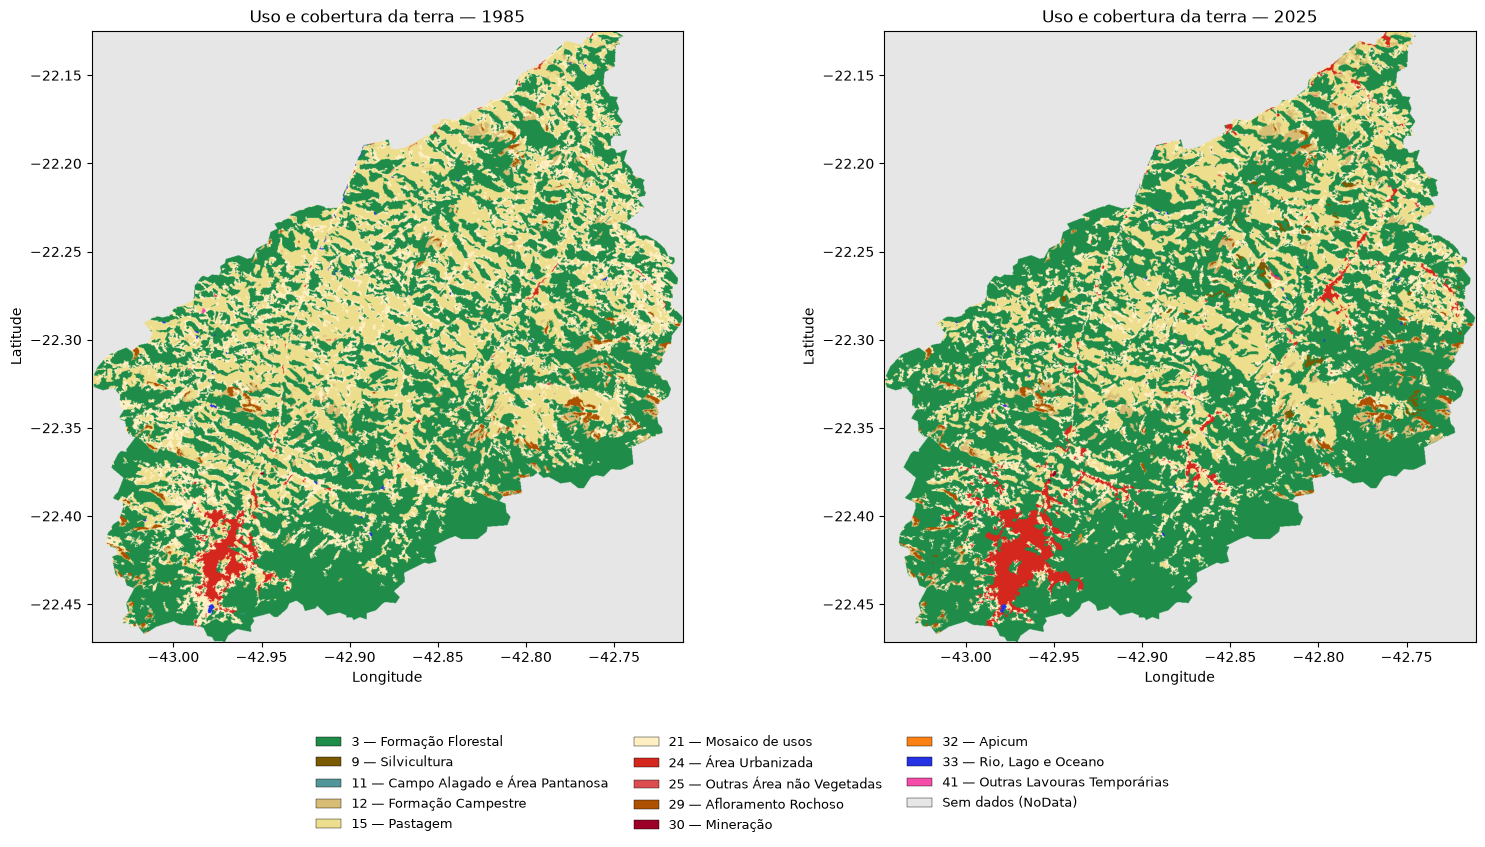

Mapa salvo em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\mapas_tematicos_1985_2025.png


In [16]:
# Criar o diretório para os resultados
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

# Anos e arquivos a visualizar
anos = [1985, 2025]
caminhos = {
    1985: arquivo_1985,
    2025: arquivo_2025,
}

# Converter cores hexadecimais para RGB
def hex_para_rgb(cor):
    cor = cor.lstrip("#")
    return tuple(
        int(cor[i:i + 2], 16)
        for i in (0, 2, 4)
    )

# Preparar a legenda comum aos dois mapas
legenda_mapa = [
    Patch(
        facecolor=cores_classes[codigo],
        edgecolor="black",
        linewidth=0.3,
        label=f"{codigo} — {nomes_classes[codigo]}"
    )
    for codigo in codigos_raster
]

# Cor de fundo para pixels NoData
cor_nodata = (230, 230, 230)

fig, eixos = plt.subplots(1, 2, figsize=(16, 8))

for ax, ano in zip(eixos, anos):
    with rasterio.open(caminhos[ano]) as src:
        dados = src.read(1, masked=True)
        limites = src.bounds

    # Criar imagem RGB
    valores = dados.filled(255)
    imagem_rgb = np.full(
        (*valores.shape, 3),
        cor_nodata,
        dtype=np.uint8
    )

    for codigo in codigos_raster:
        mascara = (~np.ma.getmaskarray(dados)) & (valores == codigo)
        imagem_rgb[mascara] = hex_para_rgb(
            cores_classes[codigo]
        )

    ax.imshow(
        imagem_rgb,
        extent=[
            limites.left,
            limites.right,
            limites.bottom,
            limites.top
        ],
        origin="upper"
    )

    ax.set_title(f"Uso e cobertura da terra — {ano}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal")

# Adicionar a indicação de NoData à legenda
legenda_mapa.append(
    Patch(
        facecolor=np.array(cor_nodata) / 255,
        edgecolor="black",
        linewidth=0.3,
        label="Sem dados (NoData)"
    )
)

fig.legend(
    handles=legenda_mapa,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.04),
    frameon=False,
    fontsize=9
)

fig.tight_layout(rect=[0, 0.16, 1, 1])

# Salvar figura
arquivo_mapa = RESULTADOS_DIR / "mapas_tematicos_1985_2025.png"

fig.savefig(
    arquivo_mapa,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mapa salvo em:", arquivo_mapa)

### Comparação visual dos mapas

Os mapas temáticos permitem comparar a distribuição espacial das classes de uso e cobertura da terra nos anos de 1985 e 2025. A interpretação deverá considerar a legenda oficial e a distribuição efetivamente observada no município.

Esta visualização tem caráter exploratório. A quantificação das mudanças será realizada nas seções seguintes, por meio do cálculo de áreas por classe e da matriz de transição entre os dois anos.

## 8. Quantificação das áreas de uso e cobertura da terra por classe

Nesta seção, será quantificada a área ocupada por cada classe de uso e cobertura da terra nos anos de 1985 e 2025.

A quantificação será realizada a partir da contagem dos pixels válidos de cada classe e do cálculo de suas áreas em hectares. Também será calculada a participação percentual de cada classe em relação à área válida analisada.

Como os rasters estão em coordenadas geográficas (EPSG:4326), a área dos pixels será calculada por método geodésico, evitando tratar graus como unidades métricas.

Os pixels NoData serão excluídos dos cálculos. Os resultados serão associados à legenda oficial do MapBiomas Coleção 11 e organizados em tabelas para comparação temporal.

### Calcular a área geodésica dos pixels

In [17]:
# Elipsoide WGS84, compatível com o datum geográfico utilizado
geod = Geod(ellps="WGS84")

def area_pixel_por_linha(transform, altura):
    """
    Calcula a área geodésica, em hectares, de um pixel
    representativo de cada linha do raster.
    """
    areas_ha = []

    for linha in range(altura):
        # Coordenadas dos limites superior e inferior da linha
        lon_esq, lat_sup = transform * (0, linha)
        lon_dir, _ = transform * (1, linha)
        _, lat_inf = transform * (0, linha + 1)

        # Área geodésica do polígono correspondente ao pixel
        area_m2, _ = geod.polygon_area_perimeter(
            [lon_esq, lon_dir, lon_dir, lon_esq],
            [lat_sup, lat_sup, lat_inf, lat_inf]
        )

        areas_ha.append(abs(area_m2) / 10_000)

    return np.asarray(areas_ha)

### Quantificar as áreas por classe

In [18]:
resultados_area = []

for ano, caminho in arquivos_entrada.items():

    with rasterio.open(caminho) as src:
        dados = src.read(1, masked=True)
        transform = src.transform
        altura, largura = dados.shape
        crs = src.crs

    if crs is None or not crs.is_geographic:
        raise ValueError(
            f"O raster de {ano} não está em CRS geográfico. "
            "Revise o método de cálculo de área."
        )

    areas_linha_ha = area_pixel_por_linha(
        transform,
        altura
    )

    area_por_classe = {}

    for linha in range(altura):
        valores_linha = dados[linha].compressed()

        if valores_linha.size == 0:
            continue

        codigos, contagens = np.unique(
            valores_linha,
            return_counts=True
        )

        for codigo, contagem in zip(codigos, contagens):
            codigo = int(codigo)

            area_ha = (
                int(contagem) * areas_linha_ha[linha]
            )

            if codigo not in area_por_classe:
                area_por_classe[codigo] = {
                    "pixels": 0,
                    "area_ha": 0.0
                }

            area_por_classe[codigo]["pixels"] += int(contagem)
            area_por_classe[codigo]["area_ha"] += area_ha

    area_total_valida = sum(
        item["area_ha"]
        for item in area_por_classe.values()
    )

    for codigo, valores in area_por_classe.items():
        resultados_area.append({
            "ano": int(ano),
            "class_id": codigo,
            "pixels": valores["pixels"],
            "area_ha": valores["area_ha"],
            "percentual": (
                valores["area_ha"] / area_total_valida * 100
                if area_total_valida > 0 else 0
            ),
        })

df_areas = pd.DataFrame(resultados_area)

print("Quantificação concluída.")
print("Total de registros:", len(df_areas))

Quantificação concluída.
Total de registros: 24


### Associar os resultados à legenda oficial

In [19]:
df_areas = df_areas.merge(
    legenda[
        ["class_id", "class_name_pt_br", "hex_code"]
    ],
    on="class_id",
    how="left",
    validate="many_to_one"
)

if df_areas["class_name_pt_br"].isna().any():
    codigos_sem_nome = (
        df_areas.loc[
            df_areas["class_name_pt_br"].isna(),
            "class_id"
        ]
        .unique()
        .tolist()
    )

    raise ValueError(
        f"Há códigos sem nome na legenda: {codigos_sem_nome}"
    )

df_areas = df_areas[
    [
        "ano",
        "class_id",
        "class_name_pt_br",
        "pixels",
        "area_ha",
        "percentual",
        "hex_code",
    ]
].sort_values(["ano", "class_id"]).reset_index(drop=True)

display(
    df_areas.style.format({
        "area_ha": "{:,.2f}",
        "percentual": "{:.2f}%"
    })
)

,ano,class_id,class_name_pt_br,pixels,area_ha,percentual,hex_code
0,1985,3,Formação Florestal,467375,"38,724.22",50.07%,#1f8d49
1,1985,9,Silvicultura,16,1.33,0.00%,#7a5900
2,1985,11,Campo Alagado e Área Pantanosa,94,7.79,0.01%,#519799
3,1985,12,Formação Campestre,21063,"1,745.37",2.26%,#d6bc74
4,1985,15,Pastagem,244091,"20,229.64",26.16%,#edde8e
5,1985,21,Mosaico de usos,178272,"14,773.16",19.10%,#ffefc3
6,1985,24,Área Urbanizada,11971,991.29,1.28%,#d4271e
7,1985,25,Outras Área não Vegetadas,350,29.00,0.04%,#db4d4f
8,1985,29,Afloramento Rochoso,8958,742.18,0.96%,#ad5100
9,1985,30,Mineração,33,2.73,0.00%,#9c0027


### Validar os totais

In [20]:
for ano, caminho in arquivos_entrada.items():

    with rasterio.open(caminho) as src:
        dados = src.read(1, masked=True)
        pixels_validos = int(dados.count())

    tabela_ano = df_areas[df_areas["ano"] == int(ano)]

    pixels_quantificados = int(tabela_ano["pixels"].sum())
    percentual_total = tabela_ano["percentual"].sum()

    print(f"\nAno: {ano}")
    print("Pixels válidos no raster:", pixels_validos)
    print("Pixels quantificados:", pixels_quantificados)
    print(f"Percentual total: {percentual_total:.6f}%")

    if pixels_quantificados != pixels_validos:
        raise ValueError(
            f"A contagem de pixels não confere para {ano}."
        )

    if not np.isclose(percentual_total, 100.0, atol=1e-6):
        raise ValueError(
            f"A soma dos percentuais não fecha em 100% para {ano}."
        )

print("\nValidação dos totais concluída.")


Ano: 1985
Pixels válidos no raster: 933319
Pixels quantificados: 933319
Percentual total: 100.000000%

Ano: 2025
Pixels válidos no raster: 933319
Pixels quantificados: 933319
Percentual total: 100.000000%

Validação dos totais concluída.


### Comparar a área total válida

In [21]:
resumo_areas = (
    df_areas.groupby("ano", as_index=False)
    .agg(
        pixels_validos=("pixels", "sum"),
        area_total_ha=("area_ha", "sum")
    )
)

resumo_areas["area_total_km2"] = (
    resumo_areas["area_total_ha"] / 100
)

display(
    resumo_areas.style.format({
        "area_total_ha": "{:,.2f}",
        "area_total_km2": "{:,.2f}"
    })
)

,ano,pixels_validos,area_total_ha,area_total_km2
0,1985,933319,"77,337.52",773.38
1,2025,933319,"77,337.52",773.38


### Exportar a tabela de áreas

In [22]:
arquivo_tabela_areas = (
    RESULTADOS_DIR / "areas_por_classe_1985_2025.csv"
)

df_areas.to_csv(
    arquivo_tabela_areas,
    index=False,
    encoding="utf-8-sig"
)

print("Tabela salva em:", arquivo_tabela_areas)

Tabela salva em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\areas_por_classe_1985_2025.csv


### Síntese da quantificação das áreas

A quantificação permite comparar a área ocupada por cada classe de uso e cobertura da terra em 1985 e 2025, tanto em hectares quanto em participação percentual na área válida analisada.

Os resultados serão utilizados na seção seguinte para calcular as variações temporais e identificar as classes que apresentaram aumento ou redução de área.

A área calculada corresponde aos pixels válidos dos rasters recortados. A interpretação deverá considerar a resolução espacial dos dados, as limitações da classificação temática e a ocorrência de eventuais diferenças entre as classes dos dois anos.

## 9. Comparação das mudanças entre 1985 e 2025

Nesta seção, serão comparadas as áreas ocupadas pelas classes de uso e cobertura da terra nos anos de 1985 e 2025.

Serão calculadas a variação absoluta da área, em hectares, a mudança na participação percentual de cada classe e a variação relativa em relação à área inicial.

Essa análise permite identificar as classes que ganharam ou perderam participação no território ao longo do período. As diferenças entre os anos representam mudanças líquidas, enquanto as transições específicas entre classes serão investigadas na seção seguinte.

### Organizar a tabela comparativa

In [23]:
# Separar as áreas por ano
tabela_area = df_areas.pivot(
    index=["class_id", "class_name_pt_br", "hex_code"],
    columns="ano",
    values="area_ha"
).fillna(0)

tabela_percentual = df_areas.pivot(
    index=["class_id", "class_name_pt_br", "hex_code"],
    columns="ano",
    values="percentual"
).fillna(0)

# Construir a tabela de comparação
df_mudancas = tabela_area.reset_index()

df_mudancas = df_mudancas.rename(columns={
    1985: "area_1985_ha",
    2025: "area_2025_ha"
})

df_mudancas["variacao_ha"] = (
    df_mudancas["area_2025_ha"]
    - df_mudancas["area_1985_ha"]
)

df_mudancas["variacao_pontos_percentuais"] = (
    tabela_percentual[2025].to_numpy()
    - tabela_percentual[1985].to_numpy()
)

# Variação relativa: não definida quando a área inicial é zero
df_mudancas["variacao_relativa_pct"] = np.nan
mascara_area_inicial = df_mudancas["area_1985_ha"] > 0

df_mudancas.loc[
    mascara_area_inicial,
    "variacao_relativa_pct"
] = (
    df_mudancas.loc[mascara_area_inicial, "variacao_ha"]
    / df_mudancas.loc[mascara_area_inicial, "area_1985_ha"]
) * 100


df_mudancas = df_mudancas.sort_values(
    "variacao_ha",
    ascending=False
).reset_index(drop=True)

display(
    df_mudancas.style.format({
        "area_1985_ha": "{:,.2f}",
        "area_2025_ha": "{:,.2f}",
        "variacao_ha": "{:+,.2f}",
        "variacao_pontos_percentuais": "{:+.2f}",
        "variacao_relativa_pct": "{:+.2f}%"
    })
)

ano,class_id,class_name_pt_br,hex_code,area_1985_ha,area_2025_ha,variacao_ha,variacao_pontos_percentuais,variacao_relativa_pct
0,3,Formação Florestal,#1f8d49,"38,724.22","45,914.73","+7,190.51",+9.30,+18.57%
1,24,Área Urbanizada,#d4271e,991.29,"2,465.87","+1,474.59",+1.91,+148.76%
2,12,Formação Campestre,#d6bc74,"1,745.37","2,355.81",+610.44,+0.79,+34.97%
3,9,Silvicultura,#7a5900,1.33,330.86,+329.53,+0.43,+24850.47%
4,25,Outras Área não Vegetadas,#db4d4f,29.00,100.54,+71.53,+0.09,+246.63%
5,30,Mineração,#9c0027,2.73,8.78,+6.05,+0.01,+221.21%
6,32,Apicum,#fc8114,0.00,6.05,+6.05,+0.01,+nan%
7,11,Campo Alagado e Área Pantanosa,#519799,7.79,10.78,+2.99,+0.00,+38.37%
8,41,Outras Lavouras Temporárias,#f54ca9,5.30,0.00,-5.30,-0.01,-100.00%
9,29,Afloramento Rochoso,#ad5100,742.18,736.30,-5.88,-0.01,-0.79%


### Conferir as mudanças líquidas

In [24]:
print("Soma das variações de área (ha):",
      round(df_mudancas["variacao_ha"].sum(), 6))

print(
    "Variação da área total (ha):",
    round(
        resumo_areas.loc[
            resumo_areas["ano"] == 2025, "area_total_ha"
        ].iloc[0]
        -
        resumo_areas.loc[
            resumo_areas["ano"] == 1985, "area_total_ha"
        ].iloc[0],
        6
    )
)

Soma das variações de área (ha): -0.0
Variação da área total (ha): -0.0


### Gráfico das variações de área

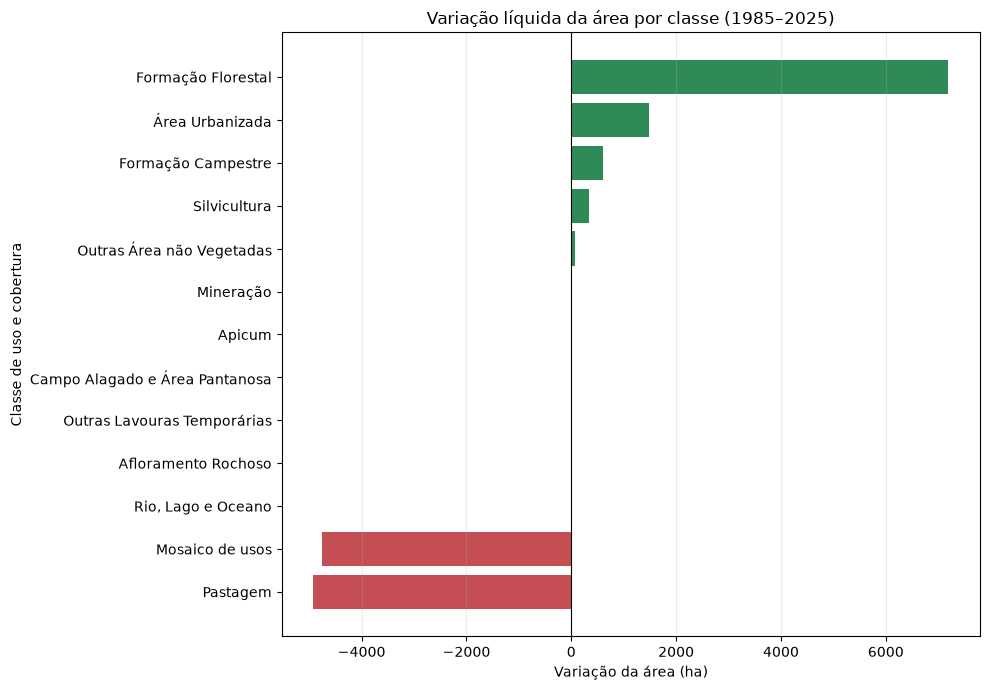

Gráfico salvo em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\variacao_area_por_classe_1985_2025.png


In [25]:
df_grafico = df_mudancas.sort_values("variacao_ha")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    df_grafico["class_name_pt_br"],
    df_grafico["variacao_ha"],
    color=[
        "#2e8b57" if valor >= 0 else "#c44e52"
        for valor in df_grafico["variacao_ha"]
    ]
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Variação líquida da área por classe (1985–2025)")
ax.set_xlabel("Variação da área (ha)")
ax.set_ylabel("Classe de uso e cobertura")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()

arquivo_grafico_mudancas = (
    RESULTADOS_DIR / "variacao_area_por_classe_1985_2025.png"
)

fig.savefig(
    arquivo_grafico_mudancas,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo em:", arquivo_grafico_mudancas)

### Exportar a tabela comparativa

In [26]:
arquivo_mudancas = (
    RESULTADOS_DIR / "mudancas_por_classe_1985_2025.csv"
)

df_mudancas.to_csv(
    arquivo_mudancas,
    index=False,
    encoding="utf-8-sig"
)

print("Tabela comparativa salva em:", arquivo_mudancas)

Tabela comparativa salva em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\mudancas_por_classe_1985_2025.csv


### Interpretação das mudanças

A comparação entre 1985 e 2025 evidencia mudanças na participação das classes de uso e cobertura da terra no município de Teresópolis.

A interpretação deve distinguir variação absoluta, variação relativa e mudança em pontos percentuais. Classes com área inicial muito pequena podem apresentar variações relativas elevadas sem representar grandes mudanças territoriais em hectares.

As diferenças líquidas entre os anos não identificam, por si só, quais classes foram convertidas em outras. A identificação dessas conversões será realizada por meio da matriz de transição.

## 10. Matriz de transição do uso e cobertura da terra (1985–2025)

Nesta seção, será construída uma matriz de transição entre as classes de uso e cobertura da terra dos anos de 1985 e 2025.

A matriz permitirá identificar a permanência das classes e as mudanças de classificação observadas entre os dois anos. Cada combinação representa uma classe inicial, em 1985, e uma classe final, em 2025.

A análise será realizada sobre pixels espacialmente correspondentes e válidos nos dois rasters. As contagens serão convertidas em áreas utilizando o cálculo geodésico dos pixels, conforme a metodologia adotada na seção anterior.

Os resultados representam transições entre classificações temáticas nos anos analisados e não demonstram, isoladamente, as causas das mudanças observadas.

### Validar a correspondência espacial e preparar os dados

In [27]:
with rasterio.open(arquivo_1985) as r85, \
     rasterio.open(arquivo_2025) as r25:

    if (
        r85.crs != r25.crs
        or r85.shape != r25.shape
        or r85.transform != r25.transform
    ):
        raise ValueError(
            "Os rasters não possuem grades espaciais compatíveis."
        )

    dados_1985 = r85.read(1, masked=True)
    dados_2025 = r25.read(1, masked=True)

    transform = r85.transform
    altura, largura = r85.shape

# Máscara comum: pixel válido nos dois anos
validos_ambos = (
    ~np.ma.getmaskarray(dados_1985)
    & ~np.ma.getmaskarray(dados_2025)
)

total_validos = int(validos_ambos.sum())

print("Dimensões:", (altura, largura))
print("Pixels válidos nos dois anos:", total_validos)
print("Pixels excluídos por NoData:", altura * largura - total_validos)

if total_validos == 0:
    raise ValueError("Não há pixels válidos simultaneamente nos dois anos.")

Dimensões: (1286, 1245)
Pixels válidos nos dois anos: 933319
Pixels excluídos por NoData: 667751


### Calcular as transições por pixel

In [28]:
transicoes_por_classe = {}

# Calcular uma única vez a área dos pixels por linha
areas_linha_ha_transicao = area_pixel_por_linha(
    transform,
    altura
)

for linha in range(altura):

    mascara_linha = validos_ambos[linha]

    if not mascara_linha.any():
        continue

    classes_1985 = dados_1985.data[linha, mascara_linha].astype(np.int32)
    classes_2025 = dados_2025.data[linha, mascara_linha].astype(np.int32)

    combinacoes, contagens = np.unique(
        np.column_stack((classes_1985, classes_2025)),
        axis=0,
        return_counts=True
    )

    area_pixel_ha = areas_linha_ha_transicao[linha]

    for (classe_inicial, classe_final), contagem in zip(
        combinacoes, contagens
    ):
        chave = (int(classe_inicial), int(classe_final))

        if chave not in transicoes_por_classe:
            transicoes_por_classe[chave] = {
                "pixels": 0,
                "area_ha": 0.0
            }

        transicoes_por_classe[chave]["pixels"] += int(contagem)
        transicoes_por_classe[chave]["area_ha"] += (
            int(contagem) * area_pixel_ha
        )

print("Combinações de classes encontradas:", len(transicoes_por_classe))

Combinações de classes encontradas: 76


### Organizar a tabela de transições

In [29]:
registros_transicoes = []

for (classe_inicial, classe_final), valores in transicoes_por_classe.items():
    registros_transicoes.append({
        "classe_1985": classe_inicial,
        "classe_2025": classe_final,
        "pixels": valores["pixels"],
        "area_ha": valores["area_ha"]
    })

df_transicoes = pd.DataFrame(registros_transicoes)

# Associar os nomes oficiais das classes
nomes_legenda = legenda.set_index("class_id")["class_name_pt_br"]

df_transicoes["nome_1985"] = df_transicoes["classe_1985"].map(nomes_legenda)
df_transicoes["nome_2025"] = df_transicoes["classe_2025"].map(nomes_legenda)

if df_transicoes[["nome_1985", "nome_2025"]].isna().any().any():
    raise ValueError("Há códigos de transição sem correspondência na legenda.")

df_transicoes = df_transicoes[
    [
        "classe_1985",
        "nome_1985",
        "classe_2025",
        "nome_2025",
        "pixels",
        "area_ha"
    ]
].sort_values("area_ha", ascending=False).reset_index(drop=True)

display(
    df_transicoes.style.format({
        "area_ha": "{:,.2f}"
    })
)

,classe_1985,nome_1985,classe_2025,nome_2025,pixels,area_ha
0,3,Formação Florestal,3,Formação Florestal,435061,"36,046.24"
1,15,Pastagem,15,Pastagem,132561,"10,987.32"
2,21,Mosaico de usos,3,Formação Florestal,75157,"6,227.92"
3,15,Pastagem,21,Mosaico de usos,53027,"4,394.35"
4,21,Mosaico de usos,21,Mosaico de usos,51576,"4,273.89"
5,15,Pastagem,3,Formação Florestal,43091,"3,570.81"
6,21,Mosaico de usos,15,Pastagem,36690,"3,041.30"
7,12,Formação Campestre,12,Formação Campestre,18368,"1,522.07"
8,3,Formação Florestal,21,Mosaico de usos,15245,"1,263.34"
9,3,Formação Florestal,15,Pastagem,14092,"1,168.02"


### Construir a matriz de transição em hectares

In [30]:
matriz_transicao_ha = df_transicoes.pivot(
    index=["classe_1985", "nome_1985"],
    columns=["classe_2025", "nome_2025"],
    values="area_ha"
).fillna(0)

display(
    matriz_transicao_ha.style.format("{:,.2f}")
)

,classe_2025,3,15,21,12,24,29,9,25,33,32,11,30
,nome_2025,Formação Florestal,Pastagem,Mosaico de usos,Formação Campestre,Área Urbanizada,Afloramento Rochoso,Silvicultura,Outras Área não Vegetadas,"Rio, Lago e Oceano",Apicum,Campo Alagado e Área Pantanosa,Mineração
classe_1985,nome_1985,,,,,,,,,,,,
3,Formação Florestal,"36,046.24","1,168.02","1,263.34",58.00,103.35,0.75,53.62,16.16,11.68,0.58,1.58,0.91
9,Silvicultura,0.00,1.33,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
11,Campo Alagado e Área Pantanosa,0.00,6.38,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.16,0.00
12,Formação Campestre,39.27,87.61,58.41,"1,522.07",24.10,5.22,0.17,1.00,2.07,5.47,0.00,0.00
15,Pastagem,"3,570.81","10,987.32","4,394.35",474.42,520.85,15.16,191.80,60.10,10.53,0.00,1.91,2.40
21,Mosaico de usos,"6,227.92","3,041.30","4,273.89",274.73,822.14,7.13,83.79,22.63,11.52,0.00,5.39,2.73
24,Área Urbanizada,1.16,0.25,1.16,0.41,988.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25,Outras Área não Vegetadas,5.30,8.62,6.88,2.16,3.89,0.00,1.49,0.66,0.00,0.00,0.00,0.00


### Validar a matriz de transição

In [31]:
pixels_transicao = int(df_transicoes["pixels"].sum())
area_transicao_ha = df_transicoes["area_ha"].sum()

print("Pixels válidos nos dois anos:", total_validos)
print("Pixels contabilizados na matriz:", pixels_transicao)
print(f"Área válida na matriz: {area_transicao_ha:,.2f} ha")

if pixels_transicao != total_validos:
    raise ValueError(
        "A contagem de pixels da matriz não corresponde "
        "à quantidade de pixels válidos."
    )

area_1985_valida = df_areas.loc[
    df_areas["ano"] == 1985, "area_ha"
].sum()

area_2025_valida = df_areas.loc[
    df_areas["ano"] == 2025, "area_ha"
].sum()

print(f"Área válida calculada em 1985: {area_1985_valida:,.2f} ha")
print(f"Área válida calculada em 2025: {area_2025_valida:,.2f} ha")

if not np.isclose(area_transicao_ha, area_1985_valida, atol=0.01):
    raise ValueError(
        "A área da matriz não corresponde à área válida de 1985."
    )

if not np.isclose(area_transicao_ha, area_2025_valida, atol=0.01):
    raise ValueError(
        "A área da matriz não corresponde à área válida de 2025."
    )

print("Validação da matriz concluída.")

Pixels válidos nos dois anos: 933319
Pixels contabilizados na matriz: 933319
Área válida na matriz: 77,337.52 ha
Área válida calculada em 1985: 77,337.52 ha
Área válida calculada em 2025: 77,337.52 ha
Validação da matriz concluída.


### Identificar as principais transições

In [32]:
df_transicoes["tipo_transicao"] = np.where(
    df_transicoes["classe_1985"] == df_transicoes["classe_2025"],
    "Permanência",
    "Mudança de classe"
)

mudancas = (
    df_transicoes[
        df_transicoes["tipo_transicao"] == "Mudança de classe"
    ]
    .sort_values("area_ha", ascending=False)
)

print("Principais mudanças entre classes:")
display(
    mudancas.head(15).style.format({
        "area_ha": "{:,.2f}"
    })
)

print("Área total de permanência (ha):",
      round(
          df_transicoes.loc[
              df_transicoes["tipo_transicao"] == "Permanência",
              "area_ha"
          ].sum(),
          2
      ))

print("Área total com mudança de classe (ha):",
      round(mudancas["area_ha"].sum(), 2))

Principais mudanças entre classes:


,classe_1985,nome_1985,classe_2025,nome_2025,pixels,area_ha,tipo_transicao
2,21,Mosaico de usos,3,Formação Florestal,75157,"6,227.92",Mudança de classe
3,15,Pastagem,21,Mosaico de usos,53027,"4,394.35",Mudança de classe
5,15,Pastagem,3,Formação Florestal,43091,"3,570.81",Mudança de classe
6,21,Mosaico de usos,15,Pastagem,36690,"3,041.30",Mudança de classe
8,3,Formação Florestal,21,Mosaico de usos,15245,"1,263.34",Mudança de classe
9,3,Formação Florestal,15,Pastagem,14092,"1,168.02",Mudança de classe
11,21,Mosaico de usos,24,Área Urbanizada,9927,822.14,Mudança de classe
13,15,Pastagem,24,Área Urbanizada,6287,520.85,Mudança de classe
14,15,Pastagem,12,Formação Campestre,5724,474.42,Mudança de classe
15,21,Mosaico de usos,12,Formação Campestre,3315,274.73,Mudança de classe


Área total de permanência (ha): 54571.44
Área total com mudança de classe (ha): 22766.08


### Exportar os resultados

In [33]:
arquivo_transicoes = (
    RESULTADOS_DIR / "transicoes_mapbiomas_1985_2025.csv"
)

arquivo_matriz = (
    RESULTADOS_DIR / "matriz_transicao_ha_1985_2025.csv"
)

df_transicoes.to_csv(
    arquivo_transicoes,
    index=False,
    encoding="utf-8-sig"
)

matriz_transicao_ha.to_csv(
    arquivo_matriz,
    encoding="utf-8-sig"
)

print("Tabela de transições salva em:", arquivo_transicoes)
print("Matriz em hectares salva em:", arquivo_matriz)

Tabela de transições salva em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\transicoes_mapbiomas_1985_2025.csv
Matriz em hectares salva em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\matriz_transicao_ha_1985_2025.csv


### Heatmap da matriz de transição

In [34]:
# preparar a matriz para o heatmap
# Matriz de transição em hectares, com códigos como índices
matriz_heatmap = df_transicoes.pivot_table(
    index="classe_1985",
    columns="classe_2025",
    values="area_ha",
    aggfunc="sum",
    fill_value=0
)

# Garantir que todas as classes encontradas apareçam nos dois eixos
codigos_todos = sorted(
    set(codigos_por_ano["1985"]) |
    set(codigos_por_ano["2025"])
)

matriz_heatmap = matriz_heatmap.reindex(
    index=codigos_todos,
    columns=codigos_todos,
    fill_value=0
)

nomes_legenda = legenda.set_index(
    "class_id"
)["class_name_pt_br"].to_dict()

rotulos = [
    f"{codigo} — {nomes_legenda[codigo]}"
    for codigo in codigos_todos
]

matriz_heatmap.index = rotulos
matriz_heatmap.columns = rotulos

display(matriz_heatmap.round(2))

,3 — Formação Florestal,9 — Silvicultura,11 — Campo Alagado e Área Pantanosa,12 — Formação Campestre,15 — Pastagem,21 — Mosaico de usos,24 — Área Urbanizada,25 — Outras Área não Vegetadas,29 — Afloramento Rochoso,30 — Mineração,32 — Apicum,"33 — Rio, Lago e Oceano",41 — Outras Lavouras Temporárias
3 — Formação Florestal,36046.24,53.62,1.58,58.00,1168.02,1263.34,103.35,16.16,0.75,0.91,0.58,11.68,0.0
9 — Silvicultura,0.00,0.00,0.00,0.00,1.33,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
11 — Campo Alagado e Área Pantanosa,0.00,0.00,1.16,0.00,6.38,0.25,0.00,0.00,0.00,0.00,0.00,0.00,0.0
12 — Formação Campestre,39.27,0.17,0.00,1522.07,87.61,58.41,24.10,1.00,5.22,0.00,5.47,2.07,0.0
15 — Pastagem,3570.81,191.80,1.91,474.42,10987.32,4394.35,520.85,60.10,15.16,2.40,0.00,10.53,0.0
21 — Mosaico de usos,6227.92,83.79,5.39,274.73,3041.30,4273.89,822.14,22.63,7.13,2.73,0.00,11.52,0.0
24 — Área Urbanizada,1.16,0.00,0.00,0.41,0.25,1.16,988.30,0.00,0.00,0.00,0.00,0.00,0.0
25 — Outras Área não Vegetadas,5.30,1.49,0.00,2.16,8.62,6.88,3.89,0.66,0.00,0.00,0.00,0.00,0.0
29 — Afloramento Rochoso,4.14,0.00,0.00,22.70,3.73,3.56,0.00,0.00,708.05,0.00,0.00,0.00,0.0
30 — Mineração,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.73,0.00,0.00,0.0


#### Versão com escala linear com valores em hectares

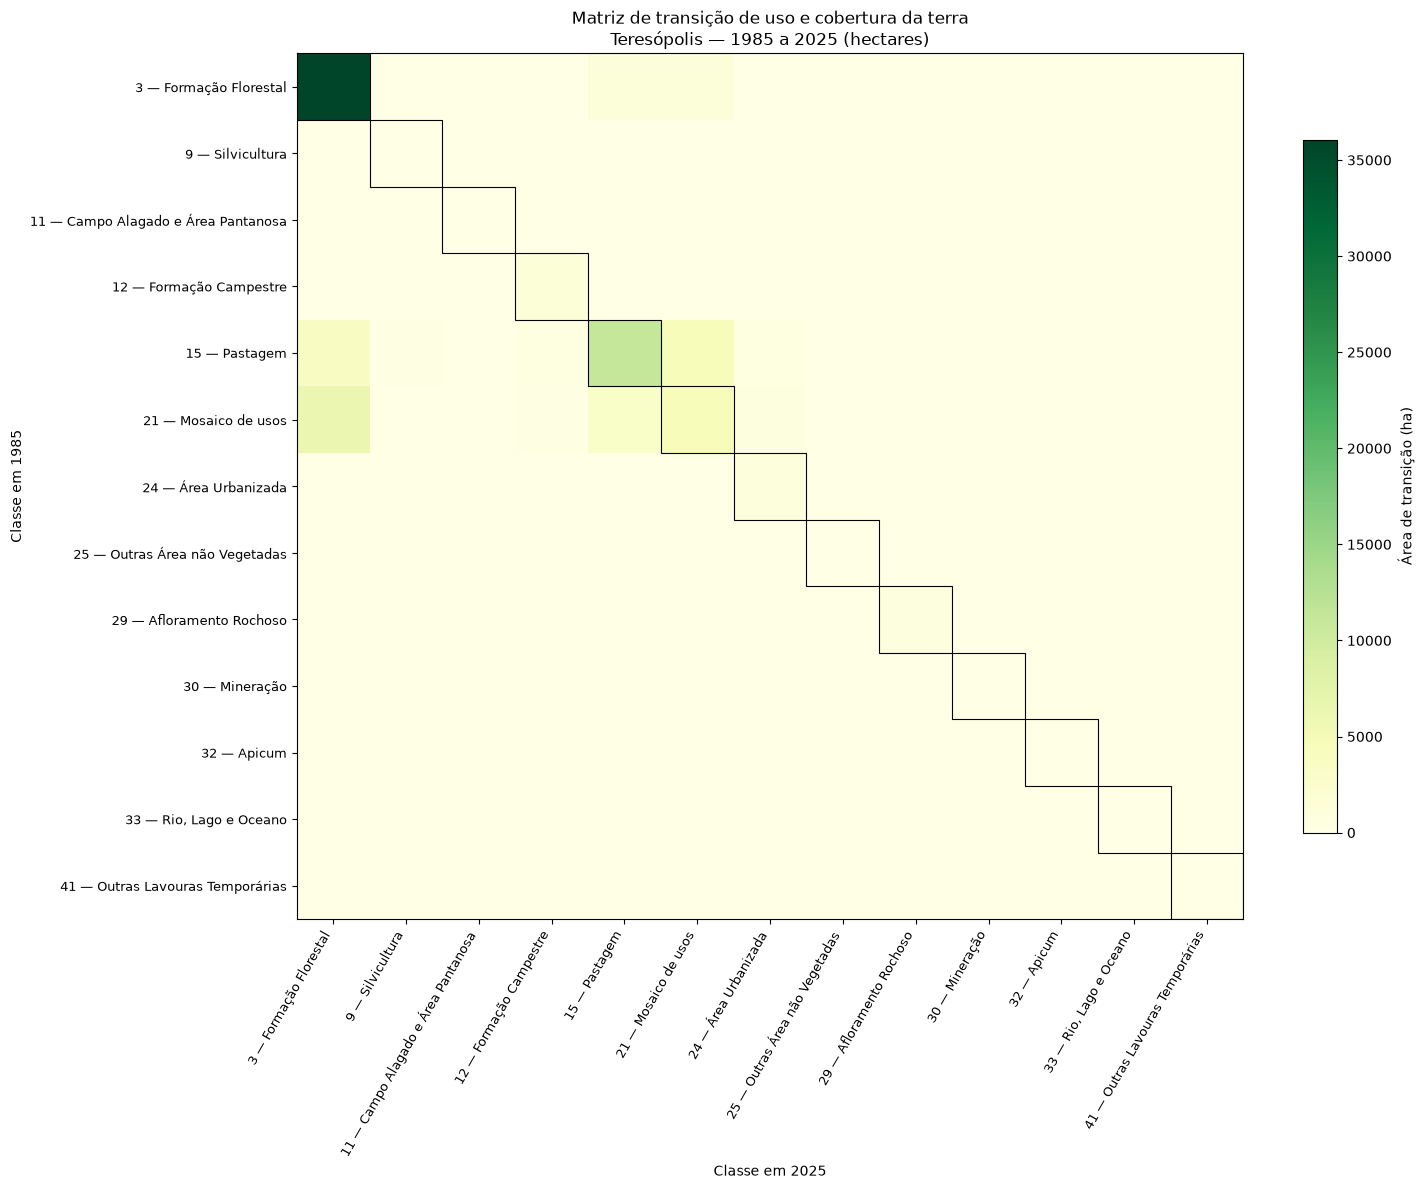

Heatmap salvo em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\heatmap_transicao_linear_1985_2025.png


In [35]:
fig, ax = plt.subplots(figsize=(15, 12))

imagem = ax.imshow(
    matriz_heatmap.values,
    cmap="YlGn",
    aspect="auto",
    interpolation="nearest"
)

# Rótulos dos eixos
ax.set_xticks(range(len(rotulos)))
ax.set_xticklabels(
    rotulos,
    rotation=60,
    ha="right",
    fontsize=9
)

ax.set_yticks(range(len(rotulos)))
ax.set_yticklabels(rotulos, fontsize=9)

ax.set_xlabel("Classe em 2025")
ax.set_ylabel("Classe em 1985")
ax.set_title(
    "Matriz de transição de uso e cobertura da terra\n"
    "Teresópolis — 1985 a 2025 (hectares)"
)

# Identificar visualmente a diagonal das permanências
for i in range(len(rotulos)):
    ax.add_patch(
        plt.Rectangle(
            (i - 0.5, i - 0.5),
            1,
            1,
            fill=False,
            edgecolor="black",
            linewidth=0.8
        )
    )

barra = fig.colorbar(imagem, ax=ax, shrink=0.8)
barra.set_label("Área de transição (ha)")

fig.tight_layout()

arquivo_heatmap_linear = (
    RESULTADOS_DIR / "heatmap_transicao_linear_1985_2025.png"
)

fig.savefig(
    arquivo_heatmap_linear,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Heatmap salvo em:", arquivo_heatmap_linear)

#### Versão com escala logarítmica

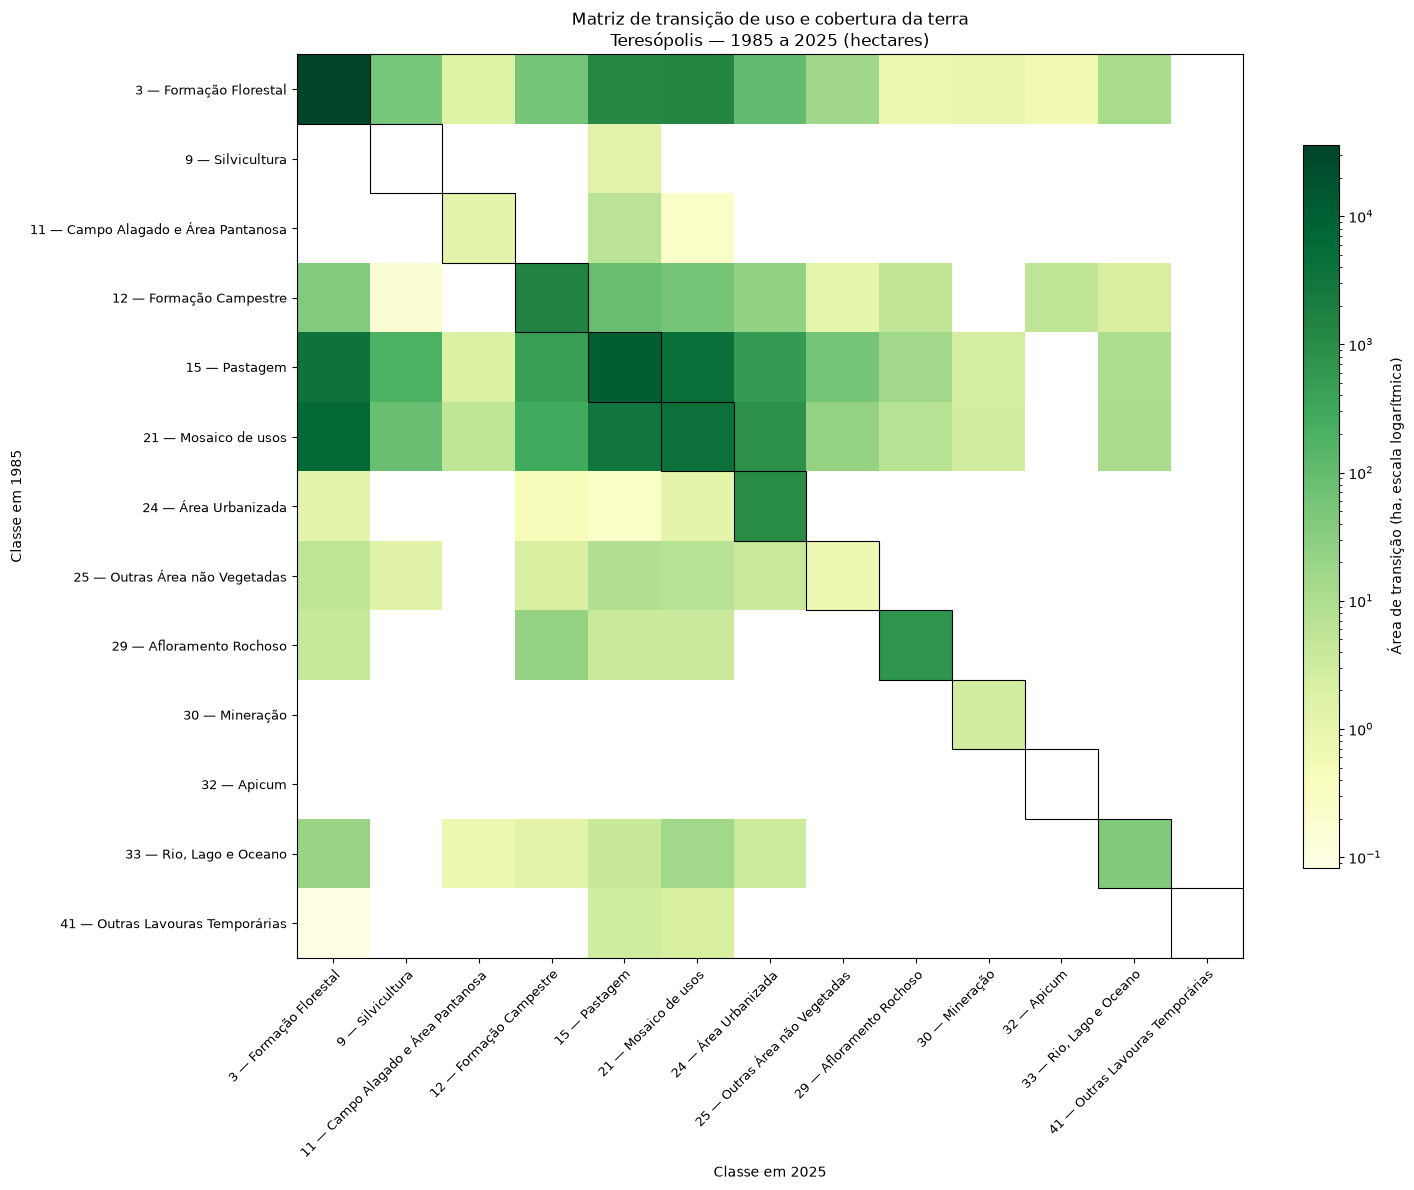

Heatmap salvo em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\heatmap_transicao_log_1985_2025.png


In [36]:
# Escala de cores logarítmica: zeros continuam claros
valores_matriz = matriz_heatmap.values
valores_positivos = valores_matriz[valores_matriz > 0]

fig, ax = plt.subplots(figsize=(15, 12))

# Usar escala logarítmica somente se houver valores positivos
imagem = ax.imshow(
    np.ma.masked_where(valores_matriz <= 0, valores_matriz),
    cmap="YlGn",
    norm=LogNorm(
        vmin=valores_positivos.min(),
        vmax=valores_positivos.max()
    ),
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(range(len(rotulos)))
ax.set_xticklabels(
    rotulos,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=9
)

ax.set_yticks(range(len(rotulos)))
ax.set_yticklabels(rotulos, fontsize=9)

ax.set_xlabel("Classe em 2025")
ax.set_ylabel("Classe em 1985")
ax.set_title(
    "Matriz de transição de uso e cobertura da terra\n"
    "Teresópolis — 1985 a 2025 (hectares)"
)

# Contorno da diagonal: permanência na mesma classe
for i in range(len(rotulos)):
    ax.add_patch(
        plt.Rectangle(
            (i - 0.5, i - 0.5),
            1, 1,
            fill=False,
            edgecolor="black",
            linewidth=0.8
        )
    )

barra = fig.colorbar(imagem, ax=ax, shrink=0.8)
barra.set_label("Área de transição (ha, escala logarítmica)")

fig.tight_layout()

arquivo_heatmap_log = (
    RESULTADOS_DIR / "heatmap_transicao_log_1985_2025.png"
)

fig.savefig(
    arquivo_heatmap_log,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Heatmap salvo em:", arquivo_heatmap_log)

### Síntese das permanências e mudanças de classe

Nesta etapa, serão quantificadas as áreas que permaneceram na mesma classe e aquelas que apresentaram mudança de classificação entre 1985 e 2025. Os resultados serão expressos em hectares e como proporção da área válida analisada, permitindo avaliar a magnitude das mudanças observadas no período.

#### calcular as áreas e proporções

In [37]:
# Consolidar áreas de permanência e mudança
resumo_transicoes = (
    df_transicoes
    .groupby("tipo_transicao", as_index=False)
    .agg(
        pixels=("pixels", "sum"),
        area_ha=("area_ha", "sum")
    )
)

area_total_ha = resumo_transicoes["area_ha"].sum()
pixels_total = resumo_transicoes["pixels"].sum()

resumo_transicoes["percentual_area"] = (
    resumo_transicoes["area_ha"] / area_total_ha * 100
)

resumo_transicoes["percentual_pixels"] = (
    resumo_transicoes["pixels"] / pixels_total * 100
)

# Ordenar para facilitar a leitura
ordem = {
    "Permanência": 0,
    "Mudança de classe": 1
}

resumo_transicoes["_ordem"] = (
    resumo_transicoes["tipo_transicao"].map(ordem)
)

resumo_transicoes = (
    resumo_transicoes
    .sort_values("_ordem")
    .drop(columns="_ordem")
    .reset_index(drop=True)
)

display(
    resumo_transicoes.style.format({
        "area_ha": "{:,.2f}",
        "percentual_area": "{:.2f}%",
        "percentual_pixels": "{:.2f}%"
    })
)

print(f"Área total analisada: {area_total_ha:,.2f} ha")
print(f"Total de pixels válidos: {pixels_total:,}")

,tipo_transicao,pixels,area_ha,percentual_area,percentual_pixels
0,Permanência,658597,"54,571.44",70.56%,70.57%
1,Mudança de classe,274722,"22,766.08",29.44%,29.43%


Área total analisada: 77,337.52 ha
Total de pixels válidos: 933,319


#### validar o resumo

In [38]:
if pixels_total != total_validos:
    raise ValueError(
        "O total de pixels do resumo não corresponde "
        "aos pixels válidos da matriz."
    )

if not np.isclose(
    resumo_transicoes["percentual_area"].sum(),
    100.0,
    atol=1e-6
):
    raise ValueError("Os percentuais de área não somam 100%.")

if set(resumo_transicoes["tipo_transicao"]) != {
    "Permanência",
    "Mudança de classe"
}:
    raise ValueError(
        "O resumo não contém as duas categorias esperadas."
    )

print("Validação do resumo concluída.")

Validação do resumo concluída.


#### selecionar as principais transições

In [39]:
principais_transicoes = (
    df_transicoes.loc[
        df_transicoes["tipo_transicao"] == "Mudança de classe"
    ]
    .sort_values("area_ha", ascending=False)
    .head(10)
    .copy()
)

principais_transicoes["percentual_area_total"] = (
    principais_transicoes["area_ha"] / area_total_ha * 100
)

display(
    principais_transicoes[
        [
            "nome_1985",
            "nome_2025",
            "pixels",
            "area_ha",
            "percentual_area_total"
        ]
    ].style.format({
        "area_ha": "{:,.2f}",
        "percentual_area_total": "{:.2f}%"
    })
)

,nome_1985,nome_2025,pixels,area_ha,percentual_area_total
2,Mosaico de usos,Formação Florestal,75157,"6,227.92",8.05%
3,Pastagem,Mosaico de usos,53027,"4,394.35",5.68%
5,Pastagem,Formação Florestal,43091,"3,570.81",4.62%
6,Mosaico de usos,Pastagem,36690,"3,041.30",3.93%
8,Formação Florestal,Mosaico de usos,15245,"1,263.34",1.63%
9,Formação Florestal,Pastagem,14092,"1,168.02",1.51%
11,Mosaico de usos,Área Urbanizada,9927,822.14,1.06%
13,Pastagem,Área Urbanizada,6287,520.85,0.67%
14,Pastagem,Formação Campestre,5724,474.42,0.61%
15,Mosaico de usos,Formação Campestre,3315,274.73,0.36%


#### exportar a síntese

In [40]:
arquivo_resumo_transicoes = (
    RESULTADOS_DIR / "resumo_permanencias_mudancas_1985_2025.csv"
)

resumo_transicoes.to_csv(
    arquivo_resumo_transicoes,
    index=False,
    encoding="utf-8-sig"
)

arquivo_principais_transicoes = (
    RESULTADOS_DIR / "principais_transicoes_1985_2025.csv"
)

principais_transicoes.to_csv(
    arquivo_principais_transicoes,
    index=False,
    encoding="utf-8-sig"
)

print("Resumo salvo em:", arquivo_resumo_transicoes)
print("Principais transições salvas em:", arquivo_principais_transicoes)

Resumo salvo em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\resumo_permanencias_mudancas_1985_2025.csv
Principais transições salvas em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\principais_transicoes_1985_2025.csv


### Interpretação da matriz de transição e limitações metodológicas

A matriz de transição, representada por um mapa de calor com escala logarítmica, permite visualizar as permanências e as mudanças nas classes de uso e cobertura da terra em Teresópolis entre 1985 e 2025. A intensidade das cores representa a magnitude das áreas envolvidas nas transições em diferentes ordens de grandeza, permitindo identificar tanto os fluxos mais expressivos quanto as transições de menor área, que seriam menos evidentes em uma escala linear. 

A diagonal principal destaca as áreas que permaneceram na mesma classe, com destaque para a Formação Florestal, enquanto as células fora da diagonal evidenciam mudanças entre categorias. Entre os fluxos mais expressivos, destacam-se as transições de Mosaico de usos para Formação Florestal, com 6.227,92 ha, de Pastagem para Mosaico de usos, com 4.394,35 ha, e de Pastagem para Formação Florestal, com 3.570,81 ha. 

Também foram identificadas transições de Mosaico de usos e Pastagem para Área Urbanizada, indicando mudanças relevantes na classificação dessas áreas ao longo do período. A escala logarítmica amplia a visibilidade das transições menores, mas as cores não representam diferenças lineares de área; por isso, os valores em hectares devem ser utilizados para comparações quantitativas. 

A matriz de transição compara as classificações dos anos de 1985 e 2025 e não identifica o momento em que as mudanças ocorreram durante o período. As transições observadas também não comprovam, isoladamente, mudanças físicas reais no território, pois podem ser influenciadas por limitações e incertezas da classificação temática.

A interpretação deve considerar a resolução espacial dos rasters, a compatibilidade das grades, a exclusão dos pixels NoData e a ocorrência de classes com áreas pequenas ou inesperadas no contexto geográfico municipal. A classe Apicum, identificada no raster de 2025, requer verificação espacial antes de receber uma interpretação ambiental.

Assim, os resultados devem ser entendidos como mudanças entre classes mapeadas, e não como demonstração direta das causas dessas mudanças.

## 11. Síntese dos resultados e exportação

Nesta seção, serão consolidados os principais resultados da análise temporal do uso e cobertura da terra em Teresópolis entre 1985 e 2025. As tabelas e figuras produzidas serão organizadas e exportadas para utilização no relatório técnico, no ebook e no portfólio do projeto.

### Consolidar indicadores gerais

In [41]:
# Indicadores gerais da análise
area_1985 = df_areas.loc[
    df_areas["ano"] == 1985, "area_ha"
].sum()

area_2025 = df_areas.loc[
    df_areas["ano"] == 2025, "area_ha"
].sum()

area_permanencia = df_transicoes.loc[
    df_transicoes["classe_1985"] == df_transicoes["classe_2025"],
    "area_ha"
].sum()

area_mudanca = df_transicoes.loc[
    df_transicoes["classe_1985"] != df_transicoes["classe_2025"],
    "area_ha"
].sum()

indicadores = pd.DataFrame({
    "Indicador": [
        "Área válida analisada (ha)",
        "Pixels válidos",
        "Área que permaneceu na mesma classe (ha)",
        "Área com mudança de classe (ha)",
        "Permanência (% da área válida)",
        "Mudança (% da área válida)",
    ],
    "Valor": [
        area_1985,
        total_validos,
        area_permanencia,
        area_mudanca,
        area_permanencia / area_1985 * 100,
        area_mudanca / area_1985 * 100,
    ]
})

display(indicadores)

,Indicador,Valor
0,Área válida analisada (ha),77337.524194
1,Pixels válidos,933319.000000
2,Área que permaneceu na mesma classe (ha),54571.440563
3,Área com mudança de classe (ha),22766.083632
4,Permanência (% da área válida),70.562694
5,Mudança (% da área válida),29.437306


### Exportar os indicadores gerais

In [42]:
arquivo_indicadores = (
    RESULTADOS_DIR / "indicadores_gerais_mapbiomas_1985_2025.csv"
)

indicadores.to_csv(
    arquivo_indicadores,
    index=False,
    encoding="utf-8-sig"
)

print("Indicadores salvos em:", arquivo_indicadores)

Indicadores salvos em: G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\indicadores_gerais_mapbiomas_1985_2025.csv


### Exportar os produtos finais

In [43]:
# Produtos finais esperados
produtos_finais = {
    "Mapa temático":
        RESULTADOS_DIR / "mapas_tematicos_1985_2025.png",

    "Áreas por classe":
        RESULTADOS_DIR / "areas_por_classe_1985_2025.csv",

    "Variação por classe":
        RESULTADOS_DIR / "mudancas_por_classe_1985_2025.csv",

    "Gráfico de variações":
        RESULTADOS_DIR / "variacao_area_por_classe_1985_2025.png",

    "Transições detalhadas":
        RESULTADOS_DIR / "transicoes_mapbiomas_1985_2025.csv",

    "Matriz de transição":
        RESULTADOS_DIR / "matriz_transicao_ha_1985_2025.csv",

    "Heatmap linear":
        RESULTADOS_DIR / "heatmap_transicao_linear_1985_2025.png",

    "Heatmap logarítmico":
        RESULTADOS_DIR / "heatmap_transicao_log_1985_2025.png",

    "Resumo de permanências e mudanças":
        RESULTADOS_DIR / "resumo_permanencias_mudancas_1985_2025.csv",

    "Principais transições":
        RESULTADOS_DIR / "principais_transicoes_1985_2025.csv",

    "Indicadores gerais":
        RESULTADOS_DIR / "indicadores_gerais_mapbiomas_1985_2025.csv",
}

for nome, caminho in produtos_finais.items():
    status = "Encontrado" if caminho.is_file() else "AINDA NÃO ENCONTRADO"
    print(f"{nome}: {status} — {caminho}")

Mapa temático: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\mapas_tematicos_1985_2025.png
Áreas por classe: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\areas_por_classe_1985_2025.csv
Variação por classe: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\mudancas_por_classe_1985_2025.csv
Gráfico de variações: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\variacao_area_por_classe_1985_2025.png
Transições detalhadas: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\transicoes_mapbiomas_1985_2025.csv
Matriz de transição: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\matriz_transicao_ha_1985_2025.csv
Heatmap linear: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\heatmap_transicao_linear_1985_2025.png
Heatmap logarítmico: Encontrado — G:\Meu Drive\projeto_teresopolis\resultados\mapbiomas\heatmap_transicao_log_1985_2025.png
Resumo de permanências e muda

### Validação de produtos ausentes

In [44]:
arquivos_ausentes = [
    caminho
    for caminho in produtos_finais.values()
    if not caminho.is_file()
]

if arquivos_ausentes:
    raise FileNotFoundError(
        "Produtos finais ausentes:\n"
        + "\n".join(str(caminho) for caminho in arquivos_ausentes)
    )

print("Auditoria concluída: todos os produtos esperados foram encontrados.")

Auditoria concluída: todos os produtos esperados foram encontrados.


## 12. Conclusão

A análise dos dados do MapBiomas Coleção 11 permitiu comparar o uso e a cobertura da terra no município de Teresópolis entre 1985 e 2025, integrando mapas temáticos, quantificação das áreas por classe e matriz de transição.

Os resultados indicaram aumento líquido da área classificada como Formação Florestal e Área Urbanizada, acompanhado pela redução das áreas classificadas como Pastagem e Mosaico de usos. A matriz de transição complementou essa comparação ao identificar as principais combinações entre classes de origem e destino, destacando a dinâmica entre formações florestais, áreas agropecuárias e áreas urbanizadas.

A interpretação desses resultados deve considerar que as diferenças representam mudanças entre classificações temáticas de dois anos distintos. A análise não determina o momento exato das transições nem comprova suas causas. A resolução espacial, as incertezas de classificação e a ocorrência de classes que exigem verificação contextual também devem ser consideradas.

Como continuidade, recomenda-se investigar espacialmente as transições mais expressivas e verificar ocorrências de classes potencialmente incompatíveis com o contexto geográfico municipal. Os resultados constituem uma base para integrar informações de relevo, solos e hidrografia nas etapas seguintes do Projeto Teresópolis.